In [1]:
import pandas as pd
import time
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression,LinearRegression
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay,mean_absolute_error,root_mean_squared_error,r2_score
)

print('All libraries loaded!')


All libraries loaded!


In [2]:
df=pd.read_csv("titanic_cleaned.csv")

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 769 entries, 0 to 768
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     769 non-null    int64  
 1   pclass       769 non-null    int64  
 2   sex          769 non-null    object 
 3   age          769 non-null    int64  
 4   sibsp        769 non-null    int64  
 5   parch        769 non-null    int64  
 6   fare         769 non-null    float64
 7   embarked     769 non-null    object 
 8   class        769 non-null    object 
 9   who          769 non-null    object 
 10  adult_male   769 non-null    bool   
 11  embark_town  769 non-null    object 
 12  alive        769 non-null    object 
 13  alone        769 non-null    bool   
dtypes: bool(2), float64(1), int64(5), object(6)
memory usage: 73.7+ KB


In [5]:
#dividing into numeric and categoric columns
num_cols = ['pclass', 'age', 'sibsp', 'parch','fare']
cat_cols = [c for c in df.columns if c not in num_cols + ["survived","alive"]]

print(f'Numeric features ({len(num_cols)}): {num_cols}')
print(f'Categorical features ({len(cat_cols)}): {cat_cols}')
print(f'\nTarget distribution:')
print(df['survived'].value_counts())
print(f'survival rate: {df["survived"].mean()*100:.1f}%')


# Build preprocessing pipeline
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])

# Train/test split (stratified — keeps churn ratio same in both sets)
X = df.drop(["survived","alive"], axis=1)
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {len(X_train):,} samples | survival rate: {y_train.mean()*100:.1f}%')
print(f'Test:  {len(X_test):,} samples  | survival rate: {y_test.mean()*100:.1f}%')


models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, random_state=42
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
}

results = []
trained_pipes = {}

for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    t0 = time.time()
    pipe.fit(X_train, y_train)
    elapsed = time.time() - t0

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=5, scoring='roc_auc')

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'cm':confusion_matrix(y_test,y_pred)
    })
    trained_pipes[name] = pipe

comparison_df = pd.DataFrame(results)
print('=' * 80)
print('BASELINE MODEL COMPARISON TABLE')
print('=' * 80)
print(comparison_df.round(4).to_string(index=False))

Numeric features (5): ['pclass', 'age', 'sibsp', 'parch', 'fare']
Categorical features (7): ['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alone']

Target distribution:
survived
0    452
1    317
Name: count, dtype: int64
survival rate: 41.2%
Train: 615 samples | survival rate: 41.3%
Test:  154 samples  | survival rate: 40.9%
BASELINE MODEL COMPARISON TABLE
              Model  Accuracy  Precision  Recall     F1  ROC-AUC                   cm
Logistic Regression    0.7987     0.7963  0.6825 0.7350   0.8380 [[80, 11], [20, 43]]
      Decision Tree    0.7662     0.8462  0.5238 0.6471   0.8301  [[85, 6], [30, 33]]
      Random Forest    0.7338     0.6833  0.6508 0.6667   0.7980 [[72, 19], [22, 41]]


Imbalance handling comparision for Decision Tree.

In [6]:
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
target = 'survived'

# Create working copy
data = df[features + [target]].copy()


# One-hot encode categorical features
data_encoded = pd.get_dummies(data, columns=['sex', 'embarked'], drop_first=True)

print(f"Clean dataset shape: {data_encoded.shape}")
print(f"Columns: {data_encoded.columns.tolist()}")
data_encoded.head()

Clean dataset shape: (769, 9)
Columns: ['pclass', 'age', 'sibsp', 'parch', 'fare', 'survived', 'sex_male', 'embarked_Q', 'embarked_S']


,pclass,age,sibsp,parch,fare,survived,sex_male,embarked_Q,embarked_S
0,3,22,1,0,7.2500,0,True,False,True
1,1,38,1,0,71.2833,1,False,False,False
2,3,26,0,0,7.9250,1,False,False,True
3,1,35,1,0,53.1000,1,False,False,True
4,3,35,0,0,8.0500,0,True,False,True


In [7]:
# Separate features and target
X1 = data_encoded.drop(target, axis=1)
y1 = data_encoded[target]

# Split: 80% train, 20% test
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42, stratify=y1
)

print(f"Training set: {X1_train.shape[0]} rows")
print(f"Test set:     {X1_test.shape[0]} rows")
print(f"\nTraining survival rate: {y1_train.mean():.1%}")
print(f"Test survival rate:     {y1_test.mean():.1%}")

Training set: 615 rows
Test set:     154 rows

Training survival rate: 41.3%
Test survival rate:     40.9%


In [8]:
tree_model = DecisionTreeClassifier(
    criterion='gini', # Entropy       # Gini Impurity (sklearn default)
    max_depth=4,             # Limit depth to prevent overfitting
    min_samples_leaf=10, # At least 10 samples per leaf
    class_weight='balanced',
    random_state=42
)


In [9]:
tree_model.fit(X1_train, y1_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=4,
                       min_samples_leaf=10, random_state=42)

In [10]:
print("✅ Decision Tree trained!")
print(f"\nTree depth: {tree_model.get_depth()}")
print(f"Number of leaves: {tree_model.get_n_leaves()}")
print(f"Number of features used: {tree_model.n_features_in_}")

✅ Decision Tree trained!

Tree depth: 4
Number of leaves: 13
Number of features used: 8


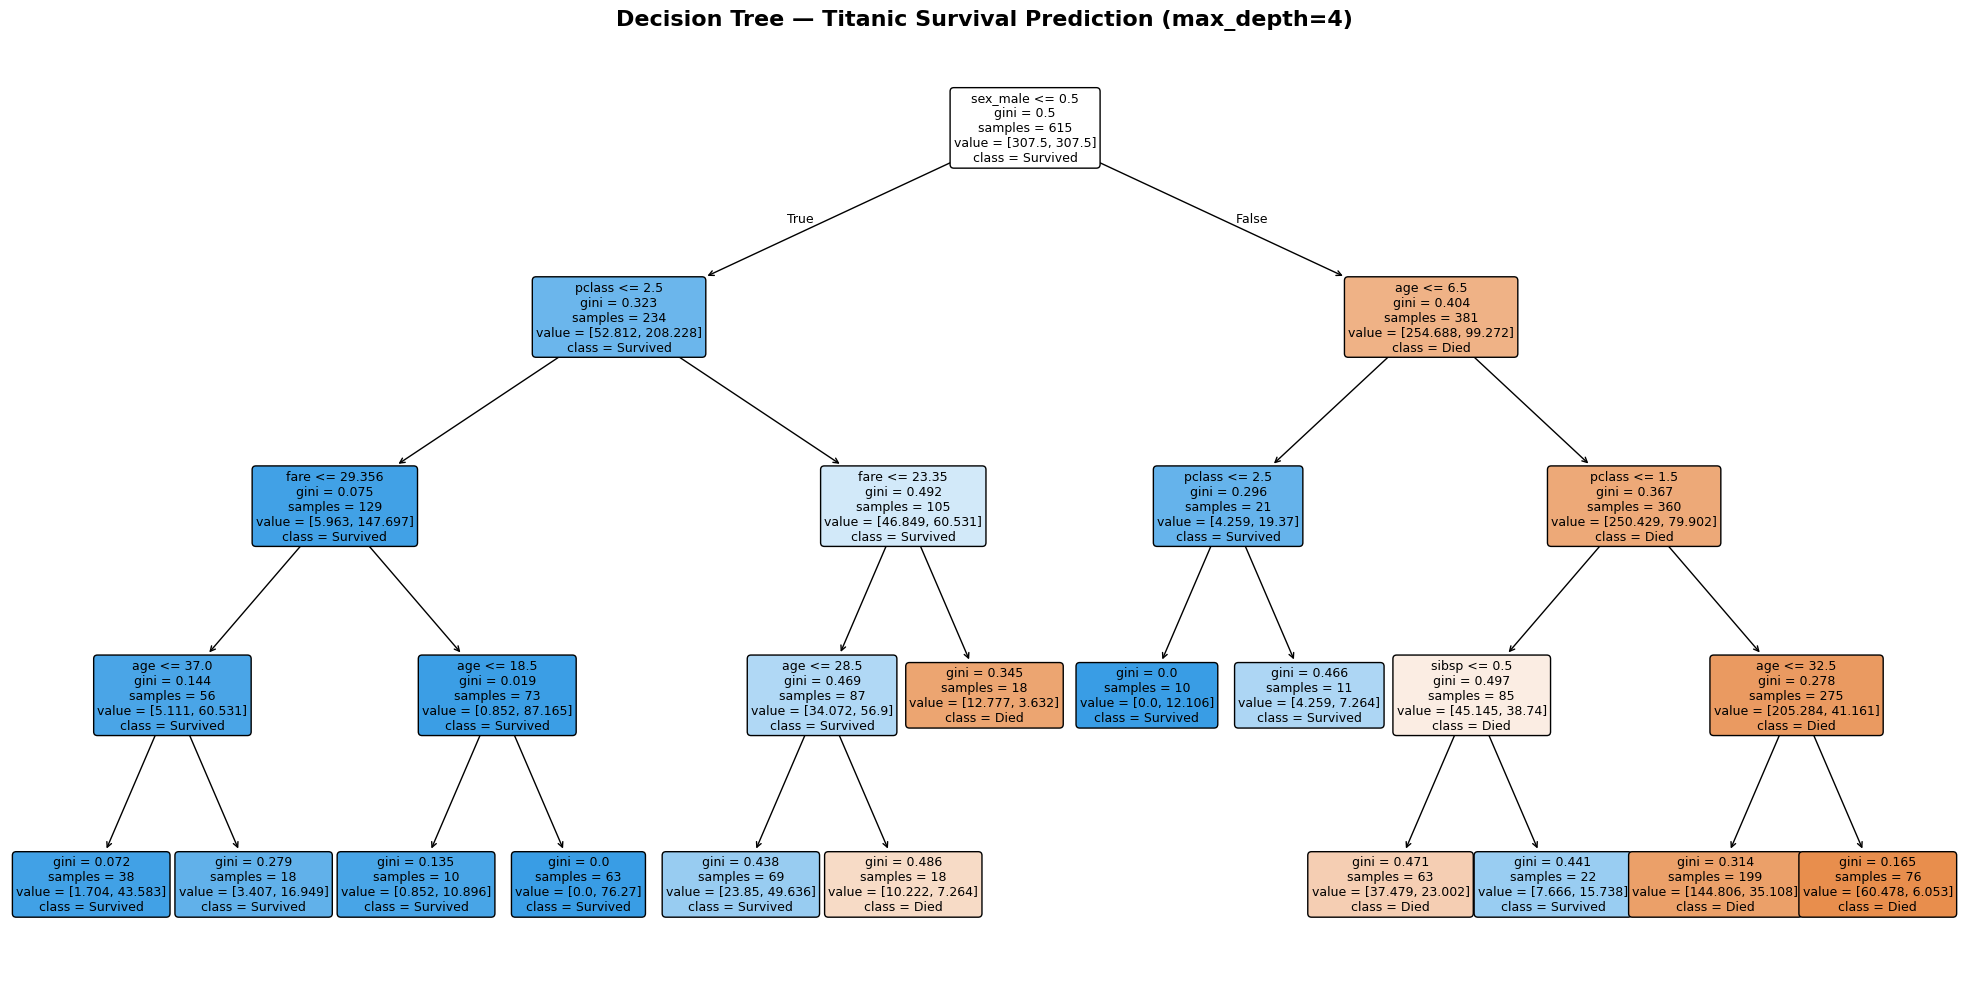

In [11]:
# Visualize the full tree
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=X1.columns.tolist(),
    class_names=['Died', 'Survived'],
    filled=True,           # Color nodes by majority class
    rounded=True,          # Rounded boxes
    fontsize=9,
    ax=ax
)
ax.set_title("Decision Tree — Titanic Survival Prediction (max_depth=4)",
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Baseline prediction of decition tree is already done in the above pipeline.

In [12]:
# Predictions
y1_pred_tree = tree_model.predict(X1_test)

# Accuracy
train_acc = tree_model.score(X1_train, y1_train)
test_acc = tree_model.score(X1_test, y1_test)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy:     {test_acc:.4f}")
print(f"Gap (overfit check): {train_acc - test_acc:.4f}")
print()

# Classification Report
print("Classification Report for balanced class weight:")
print("=" * 60)
print(classification_report(y1_test, y1_pred_tree, target_names=['Died', 'Survived']))

Training Accuracy: 0.8195
Test Accuracy:     0.7273
Gap (overfit check): 0.0922

Classification Report for balanced class weight:
              precision    recall  f1-score   support

        Died       0.76      0.78      0.77        91
    Survived       0.67      0.65      0.66        63

    accuracy                           0.73       154
   macro avg       0.72      0.72      0.72       154
weighted avg       0.73      0.73      0.73       154



In [13]:
# Fix #3: SMOTE
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X1_train_smote, y1_train_smote = smote.fit_resample(X1_train, y1_train)

print("SMOTE (Full Oversampling):")
print(f"  Before: died={int((y_train==0).sum()):,}, survived={int(y_train.sum())}")
print(f"  After:  died={int((y1_train_smote==0).sum()):,}, survived={int(y1_train_smote.sum()):,}")
print(f"  Created {len(y1_train_smote) - len(y_train):,} samples!")

SMOTE (Full Oversampling):
  Before: died=361, survived=254
  After:  died=361, survived=361
  Created 107 samples!


In [14]:
# Train on SMOTE data
tree_smote = DecisionTreeClassifier(criterion='gini',
    max_depth=4,
    min_samples_leaf=10,
    random_state=42)
tree_smote.fit(X1_train_smote, y1_train_smote)

y1_pred_smote = tree_smote.predict(X1_test)

# Accuracy
train_acc = tree_smote.score(X1_train_smote, y1_train_smote)
test_acc = tree_smote.score(X1_test, y1_test)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy:     {test_acc:.4f}")
print(f"Gap (overfit check): {train_acc - test_acc:.4f}")
print()

# Classification Report
print("Classification Report for smote:")
print("=" * 60)
print(classification_report(y1_test, y1_pred_smote, target_names=['Died', 'Survived']))

Training Accuracy: 0.7922
Test Accuracy:     0.7273
Gap (overfit check): 0.0650

Classification Report for smote:
              precision    recall  f1-score   support

        Died       0.76      0.78      0.77        91
    Survived       0.67      0.65      0.66        63

    accuracy                           0.73       154
   macro avg       0.72      0.72      0.72       154
weighted avg       0.73      0.73      0.73       154



In [15]:
#GridsearchCV for RandomForest
rf_pipeline = Pipeline([('prep', preprocessor),
 ('model', RandomForestClassifier(oob_score=True,class_weight='balanced',
                                  random_state=42,
                                  n_jobs=-1))])
param_grid = {
    "model__n_estimators" : [50, 100, 200],
    "model__max_depth" : [5, 10, None],
    "model__min_samples_split" : [2, 5, 10]
}
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
grid_search = GridSearchCV(
                        rf_pipeline,
                        param_grid,
                        cv = cv,
                        scoring = 'roc_auc',
                        n_jobs = -1,
                        verbose = 1
                    )

print("Running Grid Seach ( 27 Combinations X 5 Folds = 135 Fits)")
grid_search.fit(X_train, y_train)

Running Grid Seach ( 27 Combinations X 5 Folds = 135 Fits)
Fitting 5 folds for each of 27 candidates, totalling 135 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['pclass',
                                                                          'age',
                                                                          'sibsp',
                                                                          'parch',
                                                                          'fare']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['sex',
                                                                          'embarked',
                                                                          'class',
                                                                          'who',
                                                                          'adult_male',
                                                                          'embark_town',
                                                                          'alone'])])),
                                       ('model',
                                        RandomForestClassifier(class_weight='balanced',
                                                               n_jobs=-1,
                                                               oob_score=True,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [5, 10, None],
                         'model__min_samples_split': [2, 5, 10],
                         'model__n_estimators': [50, 100, 200]},
             scoring='roc_auc', verbose=1)

In [16]:
#printing best params and best roc_auc scores
print(f'\nBest parameters: {grid_search.best_params_}')
print(f'Best CV ROC-AUC: {grid_search.best_score_:.4f}')


Best parameters: {'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV ROC-AUC: 0.8706


In [17]:
#test scores forthe best estimator of grid search
best_rf=grid_search.best_estimator_
y_pred_rf=best_rf.predict(X_test)
y_prob_rf=best_rf.predict_proba(X_test)[:,1]
print("Test Accuracy:",accuracy_score(y_test,y_pred_rf))
print("Test ROC_AUC score:",roc_auc_score(y_test,y_prob_rf))
print()

Test Accuracy: 0.7922077922077922
Test ROC_AUC score: 0.8236525379382522



In [18]:
#oob score for best model
rf_model=best_rf.named_steps["model"]
print("OOB Score: ",rf_model.oob_score_)

OOB Score:  0.8016260162601626


Linear regression task

In [19]:
#Linear regression side task
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'embarked']
target = "fare"

# Create working copy
data_lir= df[features + [target]].copy()


# One-hot encode categorical features
data_encoded_lir = pd.get_dummies(data_lir, columns=['sex', 'embarked'], drop_first=True)

print(f"Clean dataset shape: {data_encoded_lir.shape}")
print(f"Columns: {data_encoded_lir.columns.tolist()}")
data_encoded_lir.head()

# Separate features and target
X_lir= data_encoded_lir.drop(target, axis=1)
y_lir = data_encoded_lir[target]

# Split: 80% train, 20% test
X_train_lir, X_test_lir, y_train_lir, y_test_lir = train_test_split(
    X_lir, y_lir, test_size=0.2, random_state=42
)

print(f"Training set: {X_train_lir.shape[0]} rows")
print(f"Test set:     {X_test_lir.shape[0]} rows")

Clean dataset shape: (769, 8)
Columns: ['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_male', 'embarked_Q', 'embarked_S']
Training set: 615 rows
Test set:     154 rows


In [20]:
#Linear regression model
linear_model=LinearRegression()
linear_model.fit(X_train_lir,y_train_lir)
y_pred_lir=linear_model.predict(X_test_lir)

In [23]:
#printing metrics
mae=mean_absolute_error(y_test_lir,y_pred_lir)
print("mean absolute error:",mae)
rmse=root_mean_squared_error(y_test_lir,y_pred_lir)
print("root mean square error:",rmse)
r2=r2_score(y_test_lir,y_pred_lir)
print("r2_score:",r2)
n=len(X_test_lir)
p=X_test_lir.shape[1]
adjusted_r2=1-(1-r2)*(n-1)/(n-p-1)
print("adjusted r2_score:",adjusted_r2)

mean absolute error: 22.168669769647313
root mean square error: 45.750278831165176
r2_score: 0.36246477399893673
adjusted r2_score: 0.33189801658792684


Residual plot

In [24]:
residuals=y_test_lir-y_pred_lir

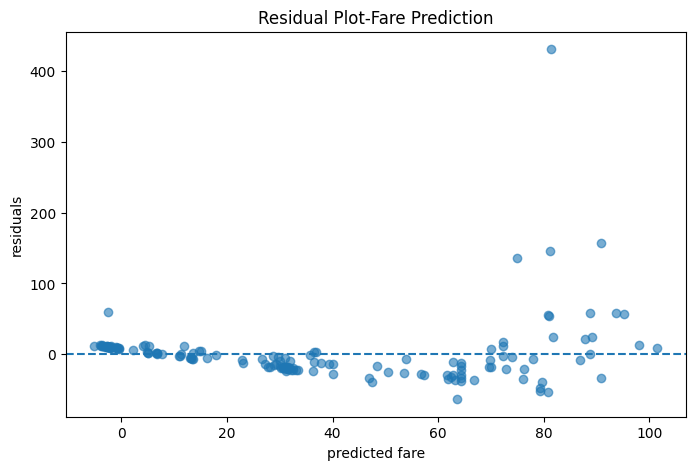

In [25]:
plt.figure(figsize=(8,5))
plt.scatter(y_pred_lir,residuals,alpha=0.6)
plt.axhline(y=0,linestyle="--")
plt.xlabel("predicted fare")
plt.ylabel("residuals")
plt.title("Residual Plot-Fare Prediction")
plt.show()

seems like the residuals are randomly distributed around zero with approximately constant variance, the heteroscedasticity is not evident.

check heteroscedasticity statistically

In [26]:
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm

X_test_with_cons=sm.add_constant(X_test_lir)

bp_result= het_breuschpagan(residuals,X_test_with_cons)

if bp_result[1]<0.05:
  print("Heteroscedasticity present")
else:
  print("No significant Heteroscedasticity")


No significant Heteroscedasticity


In [27]:
#Classification results
classification_results=pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy":[
        results[0]["Accuracy"],
        results[1]["Accuracy"],
        results[2]["Accuracy"]
    ],
    "Precision":[
        results[0]["Precision"],
        results[1]["Precision"],
        results[2]["Precision"]
    ],
    "Recall":[
        results[0]["Recall"],
        results[1]["Recall"],
        results[2]["Recall"]
    ],
    "F1_score":[
        results[0]["F1"],
        results[1]["F1"],
        results[2]["F1"]
    ],
    "ROC_AUC_score":[
        results[0]["ROC-AUC"],
        results[1]["ROC-AUC"],
        results[2]["ROC-AUC"]
    ]
})

#Regression results
regression_results=pd.DataFrame({
    "Model":[
        "Multiple Linear Regression"
    ],
    "Mae":[mae],
    "Rmse":[rmse],
    "R2":[r2],
    "Adjusted_R2":[adjusted_r2]
})

#Display classification results
print("\n")
print("="*80)
print("CLASSIFICATION MODEL COMPARISION TABLE:")
print("="*80)

print(classification_results.round(4).to_string(index=False))

#Display Regression results

print("\n")
print("="*80)
print("REGRESSION MODEL COMPARISION TABLE:")
print("="*80)

print(regression_results.round(4).to_string(index=False))



CLASSIFICATION MODEL COMPARISION TABLE:
              Model  Accuracy  Precision  Recall  F1_score  ROC_AUC_score
Logistic Regression    0.7987     0.7963  0.6825    0.7350         0.8380
      Decision Tree    0.7662     0.8462  0.5238    0.6471         0.8301
      Random Forest    0.7338     0.6833  0.6508    0.6667         0.7980


REGRESSION MODEL COMPARISION TABLE:
                     Model     Mae    Rmse     R2  Adjusted_R2
Multiple Linear Regression 22.1687 45.7503 0.3625       0.3319


saving the pipeline

In [31]:
#dumping the pipeline using joblib
joblib.dump(trained_pipes,"titanic_comparision_pipeline.pkl" )
print("All pipelines saved successfully!")

All pipelines saved successfully!


In [32]:
#loading the pickle file and saving the respected files for prediction
trained_pipes=joblib.load("titanic_comparision_pipeline.pkl")
lr_pipe=trained_pipes["Logistic Regression"]
dt_pipe=trained_pipes["Decision Tree"]
rf_pipe=trained_pipes["Random Forest"]

In [33]:
#prediction works
prediction=rf_pipe.predict(X_test)
print(prediction)

[0 1 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 0 1 0 0 0 1 1 1 0 0 1 0
 1 1 0 1 0 1 0 0 1 0 1 0 1 0 0 0 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 0 1 1 1 0 1
 0 0 0 1 0 1 0 1 0 0 0 1 1 1 0 0 0 0 0 1 0 0 1 0 1 0 1 1 1 1 0 1 0 0 0 0 0
 1 0 1 0 0 1 0 1 0 1 1 1 1 1 0 0 0 0 1 1 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 1 1
 0 1 0 1 0 1]
